**Research questions**

1. **RQ1.** Do group chats (CoCo) and public VK posts (GICR) differ in *which strategy* speakers use to refer to a woman by a noun of profession or social role: a suffixal feminitive (*авторка*), a masculine noun with feminine agreement (*наша врач*, *врач сказала*) or an analytic construction (*женщина-врач*)?
2. **RQ2.** Is the choice of a feminitive suffix a property of the individual base rather than of global suffix productivity? (A suggestion from the proposal review: *автор + -ка* may be frequent while *доктор* prefers another suffix.)
3. **RQ3.** Does the competition between suffixes inside one base look the same in both corpora?

**Hypotheses**

* **H1.** Spontaneous chat talk relies more on morphological feminitives and on colloquial suffixes (*-ša*, *-ixa*) than public VK posts.
* **H2.** Suffix choice is strongly predicted by the base and its derivational class; a global ranking of suffixes hides this.
* **H3.** Bases with real competition (several suffixes in use) differ between the corpora more than bases with one established feminitive.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.spatial.distance import jensenshannon
from sklearn.decomposition import PCA

DATA, FIG = Path("../data"), Path("../figures")
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
PALETTE = {"CoCo": "#d1495b", "GICR": "#00798c"}

## 1. Data

* **CoCo (Corpus of Correspondence)** — Telegram group chats on different topics (sport, games, university dormitories, fandoms, finance).
  The raw chats are private and are **not** published; `src/coco_search.py` scans them locally and writes only aggregated counts.
* **GICR (General Internet Corpus of Russian, VK section)** — the 2026 version of GICR inside the Russian National Corpus.
  Counts were collected with the public RNC API (`src/gicr_collect.py`), one query per item, without downloading texts.
* **Lexicon** (`data/lexicon.csv`) — masculine bases of profession/role nouns grouped by derivational class, each with the feminitive lemmas attested in usage or dictionaries, built with six suffixes: *-ka* (авторка), *-ica* (учительница), *-ša* (директорша), *-ixa* (врачиха), *-essa/-isa* (поэтесса, директриса), *-inja* (психологиня).

In [2]:
lex = pd.read_csv(DATA / "lexicon.csv")
sizes = pd.concat([pd.read_csv(DATA / "coco_size.csv"), pd.read_csv(DATA / "gicr_size.csv")])
WORDS = dict(zip(sizes.corpus, sizes.words))

coco = pd.read_csv(DATA / "coco_counts.csv").assign(corpus="CoCo")
gicr = pd.read_csv(DATA / "gicr_counts.csv").assign(corpus="GICR")

# Two-word RNC queries count words and ignore punctuation, so «...м. Нагорная. Тренер: ...»
# can match «feminine adjective + тренер». gicr_precision.csv stores the share of clean
# concordance lines in a sample for every such query; raw counts are scaled by it.
prec = pd.read_csv(DATA / "gicr_precision.csv")
prec["precision"] = (prec.clean / prec.sampled.replace(0, np.nan)).astype(float)
type_mean = prec.groupby("query_type").precision.mean()
gicr = gicr.merge(prec[["base", "query_type", "precision"]], on=["base", "query_type"], how="left")
gicr["precision"] = gicr.precision.fillna(gicr.query_type.map(type_mean)).fillna(1.0).astype(float)
gicr["raw_hits"] = gicr.hits
gicr["hits"] = gicr.hits * gicr.precision

counts = pd.concat([coco, gicr], ignore_index=True)[["corpus", "base", "query_type", "item", "label", "hits"]]
counts["ipm"] = counts.hits / counts.corpus.map(WORDS) * 1e6
counts = counts.merge(lex[["base", "deriv_class"]].drop_duplicates(), on="base", how="left")

print(f"lexicon: {lex.base.nunique()} bases, {lex.deriv_class.nunique()} derivational classes, "
      f"{lex.fem_lemma.nunique()} feminitive lemmas")
sizes[["corpus", "words"]].assign(words=lambda d: d.words.map("{:,}".format))

lexicon: 50 bases, 11 derivational classes, 88 feminitive lemmas


,corpus,words
0,CoCo,"24,407,834"
0,GICR,"15,561,755,506"


In [3]:
print("GICR two-word queries: mean share of clean concordance lines")
prec.groupby("query_type")[["sampled", "clean"]].sum().assign(precision=lambda d: d.clean / d.sampled)

GICR two-word queries: mean share of clean concordance lines


,sampled,clean,precision
query_type,,,
agree_adj,400,288,0.720
agree_verb,750,570,0.760
analytic,525,97,0.185


## 2. RQ1 — strategies of feminine reference

To compare strategies on equal terms, only **nominative singular** mentions are counted: a feminitive in nom.sg (*авторка*),
a masculine base in nom.sg with an adjacent feminine adjective/pronoun (*наша врач*) or a feminine past-tense verb (*врач сказала*),
and *женщина* + base in nom.sg. Agreement is only caught in these adjacent frames, so its share is a **lower bound**.

In [4]:
STRATEGY = {"suffix_nomsg": "feminitive", "agree_adj": "agreement", "agree_verb": "agreement", "analytic": "analytic"}
strat = (counts[counts.query_type.isin(STRATEGY)]
         .assign(strategy=lambda d: d.query_type.map(STRATEGY))
         .groupby(["corpus", "strategy"])[["hits", "ipm"]].sum().reset_index())
table = strat.pivot(index="strategy", columns="corpus", values="hits").fillna(0)
share = table / table.sum() * 100


def cramers_v(tab):
    tab = tab.astype(float)
    chi2, p, dof, _ = chi2_contingency(tab)
    n = tab.to_numpy().sum()
    return chi2, p, dof, np.sqrt(chi2 / (n * (min(tab.shape) - 1)))


chi2, p, dof, v = cramers_v(table.round())
print(f"strategy x corpus: chi2={chi2:.1f}, df={dof}, p={p:.2g}, Cramer's V={v:.3f}")
pd.concat({"tokens": table.round(), "share, %": share, "ipm": strat.pivot(index="strategy", columns="corpus", values="ipm")}, axis=1)

strategy x corpus: chi2=8.7, df=2, p=0.013, Cramer's V=0.004


tokens           share, %             ipm        
corpus       CoCo      GICR     CoCo    GICR    CoCo    GICR
strategy                                                    
agreement    65.0   98614.0   14.541  17.293   2.663   6.337
analytic      4.0    1527.0    0.895   0.268   0.164   0.098
feminitive  378.0  470127.0   84.564  82.440  15.487  30.210

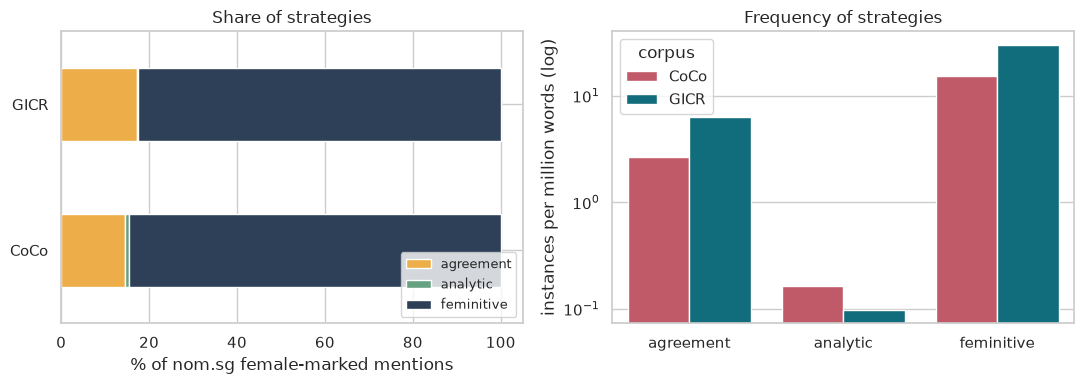

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
share.T.plot.barh(stacked=True, ax=axes[0], color=["#edae49", "#66a182", "#2e4057"])
axes[0].set(xlabel="% of nom.sg female-marked mentions", ylabel="", title="Share of strategies")
axes[0].legend(loc="lower right", fontsize=9)
sns.barplot(data=strat, x="strategy", y="ipm", hue="corpus", palette=PALETTE, ax=axes[1])
axes[1].set(yscale="log", ylabel="instances per million words (log)", xlabel="", title="Frequency of strategies")
fig.tight_layout()
fig.savefig(FIG / "strategies.png", dpi=150)

## 3. Feminitives: how often and with which suffix

All inflected forms of the 86 feminitive lemmas. The *feminitive rate* of a base is the number of feminitive tokens
per 100 tokens of the masculine base: it shows how often a base is feminized at all.

In [6]:
fem = counts[counts.query_type == "suffix"]
suf = fem.groupby(["corpus", "label"]).hits.sum().unstack(0).fillna(0)
suf_share = suf / suf.sum() * 100
chi2, p, dof, v = cramers_v(suf.round())
print(f"suffix x corpus: chi2={chi2:.1f}, df={dof}, p={p:.2g}, Cramer's V={v:.3f}")
overall = fem.groupby("corpus")[["hits", "ipm"]].sum()
display(overall)
suf_share.sort_values("GICR", ascending=False)

suffix x corpus: chi2=454.9, df=5, p=4.2e-96, Cramer's V=0.022


,hits,ipm
corpus,,
CoCo,752.0,30.810
GICR,962091.0,61.824


corpus,CoCo,GICR
label,,
-ica,74.734,78.596
-ka,11.436,10.806
-essa,4.654,6.672
-ša,3.059,2.368
-ixa,2.660,1.377
-inja,3.457,0.181


bases above the diagonal (feminized more often in chats): 16 of 25


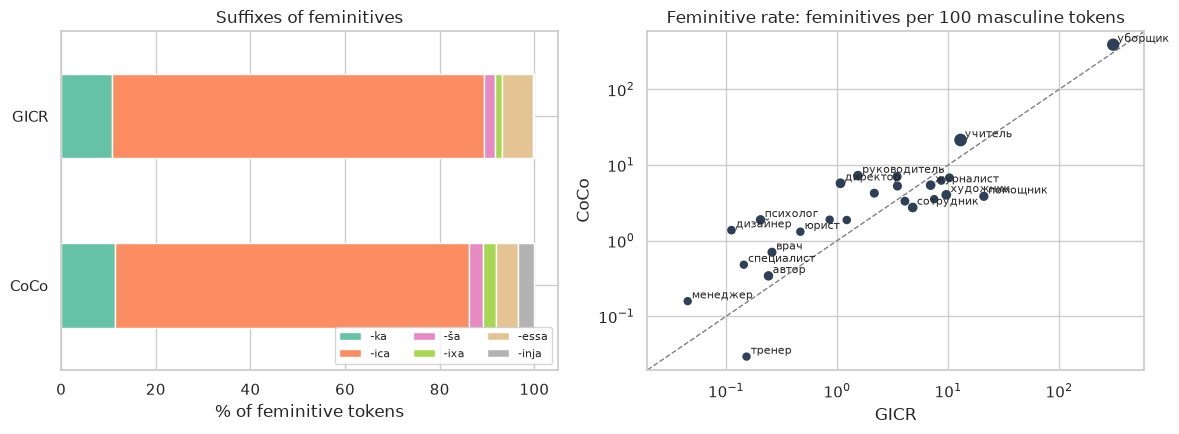

In [7]:
base_tot = counts[counts.query_type == "base_total"].groupby(["corpus", "base"]).hits.sum()
fem_tot = fem.groupby(["corpus", "base"]).hits.sum()
rate = (fem_tot / base_tot * 100).rename("rate").reset_index().pivot(index="base", columns="corpus", values="rate")
rate = rate.join(fem_tot.unstack(0).add_prefix("n_"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
suf_share.T[["-ka", "-ica", "-ša", "-ixa", "-essa", "-inja"]].plot.barh(stacked=True, ax=axes[0], colormap="Set2")
axes[0].set(xlabel="% of feminitive tokens", ylabel="", title="Suffixes of feminitives")
axes[0].legend(ncol=3, fontsize=8, loc="lower right")
r = rate[(rate.n_CoCo >= 3) & (rate.GICR > 0)]
axes[1].scatter(r.GICR, r.CoCo, s=20 + 3 * np.sqrt(r.n_CoCo), color="#2e4057")
# label only bases far from the diagonal or frequent in CoCo, the dense middle stays readable
far = np.abs(np.log10(r.CoCo / r.GICR)) > 0.4
for b, row in r[far | (r.n_CoCo >= 20)].iterrows():
    axes[1].annotate(b, (row.GICR, row.CoCo), fontsize=8, xytext=(3, 2), textcoords="offset points")
lim = [min(r.GICR.min(), r.CoCo.min()) / 1.5, max(r.GICR.max(), r.CoCo.max()) * 1.5]
axes[1].plot(lim, lim, ls="--", color="grey", lw=1)
axes[1].set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="GICR", ylabel="CoCo",
            title="Feminitive rate: feminitives per 100 masculine tokens")
fig.tight_layout()
fig.savefig(FIG / "suffixes_and_rate.png", dpi=150)
print("bases above the diagonal (feminized more often in chats):", int((r.CoCo > r.GICR).sum()), "of", len(r))

## 4. RQ2 — suffix competition inside a base

For every base we take the distribution of its feminitive tokens over suffixes and compute Shannon entropy (bits):
0 means one suffix only, 1 bit means two equally used suffixes. If suffix choice followed global productivity,
every base would repeat the global distribution of section 3.

In [8]:
def entropy_bits(p):
    p = p[p > 0] / p.sum()
    return float(-(p * np.log2(p)).sum())


dist = fem.groupby(["corpus", "base", "label"]).hits.sum().unstack("label").fillna(0)
comp = pd.DataFrame({
    "n": dist.sum(axis=1),
    "top_suffix": dist.idxmax(axis=1),
    "top_share": dist.max(axis=1) / dist.sum(axis=1),
    "entropy": dist.apply(entropy_bits, axis=1),
}).reset_index()
comp = comp.merge(lex[["base", "deriv_class"]].drop_duplicates(), on="base")
competing = comp[(comp.corpus == "GICR") & (comp.n >= 30)].sort_values("entropy", ascending=False)
competing.head(12)

,corpus,base,n,top_suffix,top_share,entropy,deriv_class
39,GICR,агент,809.0,-ka,0.419,1.549,-ant/-ent
40,GICR,адвокат,827.0,-essa,0.502,1.313,-at
38,GICR,автор,8110.0,-ka,0.641,1.017,-or/-er
74,GICR,редактор,647.0,-ša,0.553,0.992,-or/-er
54,GICR,завуч,148.0,-ixa,0.561,0.989,other
49,GICR,депутат,2868.0,-ka,0.585,0.979,-at
60,GICR,менеджер,183.0,-ka,0.639,0.943,-or/-er
68,GICR,президент,1287.0,-ša,0.651,0.933,-ant/-ent
72,GICR,психолог,1218.0,-inja,0.779,0.921,-log
50,GICR,дизайнер,470.0,-ša,0.670,0.915,-or/-er


In [9]:
g = dist.loc["GICR"]
g = g[g.sum(axis=1) >= 30]
global_p = g.sum() / g.sum().sum()
jsd_global = g.apply(lambda row: jensenshannon(row / row.sum(), global_p, base=2), axis=1)
print(f"global suffix distribution (GICR): entropy = {entropy_bits(g.sum()):.2f} bits")
print(f"mean within-base entropy (GICR, n>=30): {comp[(comp.corpus=='GICR') & (comp.n>=30)].entropy.mean():.2f} bits")
print(f"bases where one suffix takes >90% of tokens: {(g.max(axis=1) / g.sum(axis=1) > .9).mean():.0%}")
print(f"mean Jensen-Shannon distance base vs global: {jsd_global.mean():.2f}")

cls = fem[fem.corpus == "GICR"].groupby(["deriv_class", "label"]).hits.sum().unstack().fillna(0)
chi2, p, dof, v = cramers_v(cls.round())
print(f"derivational class x suffix (GICR): Cramer's V = {v:.2f}")

global suffix distribution (GICR): entropy = 1.11 bits
mean within-base entropy (GICR, n>=30): 0.37 bits
bases where one suffix takes >90% of tokens: 61%
mean Jensen-Shannon distance base vs global: 0.74
derivational class x suffix (GICR): Cramer's V = 0.83


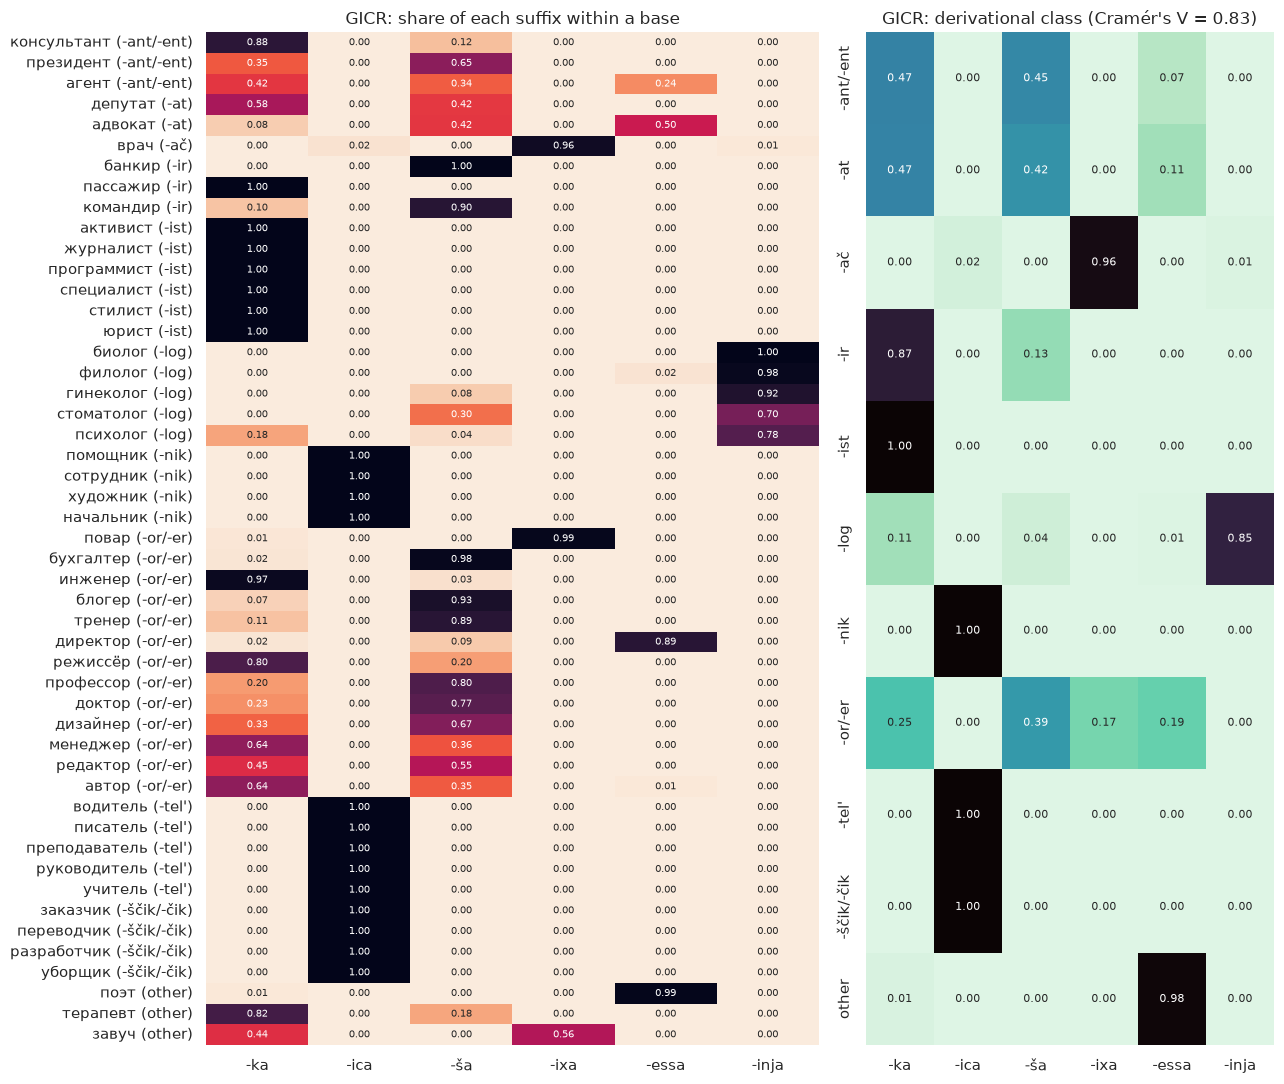

In [10]:
order = g.div(g.sum(axis=1), axis=0)
order = order.loc[comp[(comp.corpus == "GICR") & (comp.n >= 30)].sort_values(["deriv_class", "entropy"]).base]
order.index = [f"{b} ({c})" for b, c in zip(order.index, lex.drop_duplicates("base").set_index("base").loc[order.index].deriv_class)]
fig, axes = plt.subplots(1, 2, figsize=(13, 11), gridspec_kw={"width_ratios": [3, 2]})
sns.heatmap(order[["-ka", "-ica", "-ša", "-ixa", "-essa", "-inja"]], cmap="rocket_r", annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar=False, ax=axes[0])
axes[0].set(title="GICR: share of each suffix within a base", xlabel="", ylabel="")
cls_share = cls.div(cls.sum(axis=1), axis=0)[["-ka", "-ica", "-ša", "-ixa", "-essa", "-inja"]]
sns.heatmap(cls_share, cmap="mako_r", annot=True, fmt=".2f", annot_kws={"size": 8}, cbar=False, ax=axes[1])
axes[1].set(title=f"GICR: derivational class (Cramér's V = {v:.2f})", xlabel="", ylabel="")
fig.tight_layout()
fig.savefig(FIG / "suffix_by_base.png", dpi=150)

## 5. RQ3 — the same bases in two corpora

Bases with at least 5 feminitive tokens in CoCo are compared with GICR: does the dominant suffix coincide,
and how far apart are the two distributions (Jensen–Shannon distance, 0 = identical, 1 = disjoint)?

In [11]:
both = comp.pivot(index="base", columns="corpus", values=["n", "top_suffix", "entropy"])
both = both[(both[("n", "CoCo")] >= 5) & (both[("n", "GICR")] >= 5)]
rows = []
for b in both.index:
    pc, pg = dist.loc[("CoCo", b)], dist.loc[("GICR", b)]
    rows.append({"base": b, "n_CoCo": int(pc.sum()), "n_GICR": int(pg.sum()),
                 "top_CoCo": pc.idxmax(), "top_GICR": pg.idxmax(),
                 "H_CoCo": entropy_bits(pc), "H_GICR": entropy_bits(pg),
                 "JSD": jensenshannon(pc / pc.sum(), pg / pg.sum(), base=2)})
cross = pd.DataFrame(rows).sort_values("JSD", ascending=False)
print(f"same dominant suffix in {(cross.top_CoCo == cross.top_GICR).mean():.0%} of {len(cross)} bases")
print(f"Spearman rho(H_GICR, JSD) = {cross[['H_GICR', 'JSD']].corr(method='spearman').iloc[0, 1]:.2f}")
cross

same dominant suffix in 94% of 18 bases
Spearman rho(H_GICR, JSD) = 0.91


,base,n_CoCo,n_GICR,top_CoCo,top_GICR,H_CoCo,H_GICR,JSD
3,врач,13,5481,-ixa,-ixa,1.526,0.289,0.552
4,дизайнер,6,470,-ka,-ša,0.650,0.915,0.445
12,психолог,20,1218,-inja,-inja,0.748,0.921,0.301
7,начальник,9,24430,-ica,-ica,0.503,0.008,0.235
0,автор,21,8110,-ka,-ka,0.592,1.017,0.221
2,блогер,14,7933,-ša,-ša,0.750,0.362,0.181
5,директор,30,9832,-essa,-essa,0.211,0.558,0.139
9,повар,13,7980,-ixa,-ixa,-0.000,0.108,0.085
1,активист,7,29570,-ka,-ka,-0.000,-0.000,0.000
6,журналист,25,41267,-ka,-ka,-0.000,-0.000,0.000


bases with a single suffix in both corpora: активист, журналист, писатель, помощник, преподаватель, руководитель, сотрудник, уборщик, учитель, художник


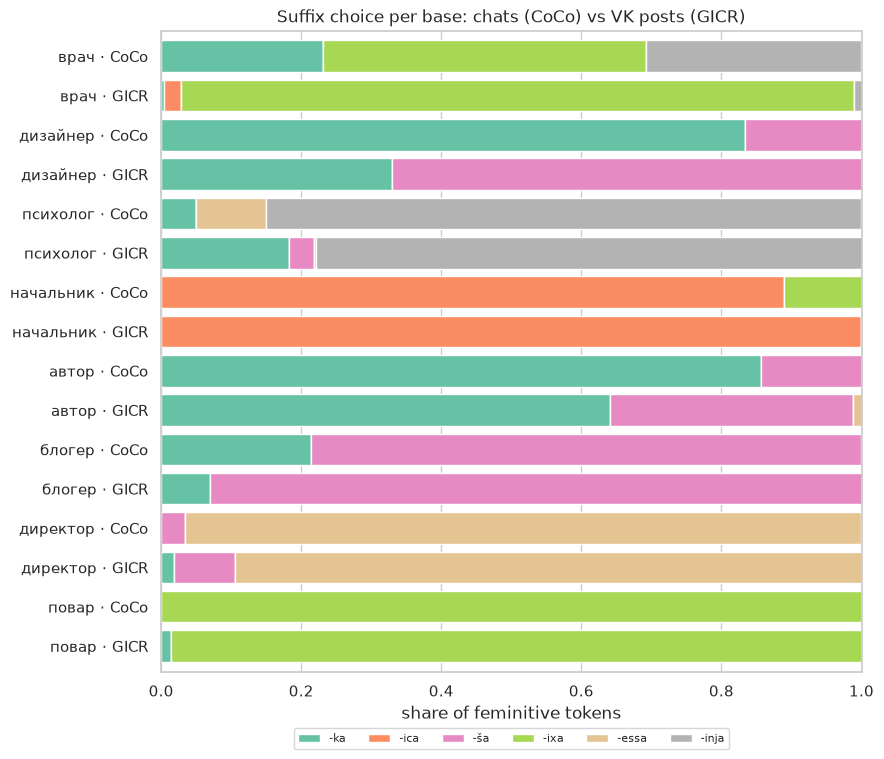

In [12]:
# bases with one suffix in both corpora are identical bars; plot only bases with some competition
sel = cross[(cross.H_CoCo > 0.05) | (cross.H_GICR > 0.05)].base.tolist()
print("bases with a single suffix in both corpora:", ", ".join(cross[~cross.base.isin(sel)].base))
sh = dist.div(dist.sum(axis=1), axis=0)[["-ka", "-ica", "-ša", "-ixa", "-essa", "-inja"]]
pairs = pd.concat({c: sh.loc[c].loc[sel] for c in ["CoCo", "GICR"]}).swaplevel().sort_index(level=0, sort_remaining=False)
pairs = pairs.loc[sel]
pairs.index = [f"{b} · {c}" for b, c in pairs.index]
ax = pairs.plot.barh(stacked=True, figsize=(9, 0.42 * len(pairs) + 1), colormap="Set2", width=0.8)
ax.invert_yaxis()
ax.set(xlabel="share of feminitive tokens", title="Suffix choice per base: chats (CoCo) vs VK posts (GICR)")
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(FIG / "cross_corpus_bases.png", dpi=150)

## 6. A typological map of bases

Each base is a vector of suffix shares (a base × suffix matrix, as in the typological matrices of the course).
PCA reduces it to two dimensions; colours mark derivational classes. Arrows lead from the GICR position of a base
to its CoCo position (bases with ≥5 CoCo tokens).

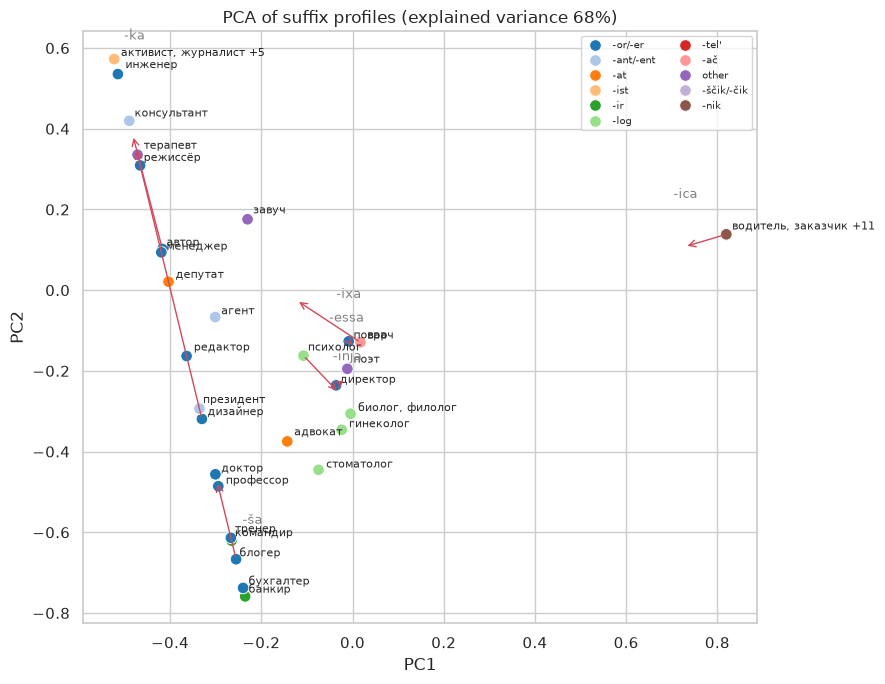

In [13]:
M = sh.loc["GICR"]
M = M[g.reindex(M.index).sum(axis=1).fillna(0) >= 30]
pca = PCA(n_components=2).fit(M)
xy = pd.DataFrame(pca.transform(M), index=M.index, columns=["PC1", "PC2"])
xy["class"] = lex.drop_duplicates("base").set_index("base").loc[xy.index].deriv_class
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=xy, x="PC1", y="PC2", hue="class", s=70, ax=ax, palette="tab20")
# bases with an identical profile (e.g. all -nik/-tel'/-ščik → 100% -ica) share one point and one label
for (x, y), group in xy.groupby([xy.PC1.round(2), xy.PC2.round(2)]):
    names = list(group.index)
    label = ", ".join(names) if len(names) <= 2 else f"{', '.join(names[:2])} +{len(names) - 2}"
    ax.annotate(label, (x, y), fontsize=8, xytext=(4, 3), textcoords="offset points")
for b in [b for b in sel if b in xy.index]:
    c = pca.transform(sh.loc[("CoCo", b)].to_frame().T)[0]
    ax.annotate("", xy=c, xytext=(xy.loc[b, "PC1"], xy.loc[b, "PC2"]),
                arrowprops=dict(arrowstyle="->", color=PALETTE["CoCo"], lw=1))
for i, s in enumerate(M.columns):
    ax.annotate(s, pca.components_[:, i] * 0.9, color="grey", fontsize=9, ha="center")
ax.set(title=f"PCA of suffix profiles (explained variance {pca.explained_variance_ratio_.sum():.0%})")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIG / "pca_map.png", dpi=150)

## 7. Where do CoCo feminitives come from?

CoCo is small, so a frequent item may come from a single chat. The number of chats an item occurs in (its range) shows how robust it is.

In [14]:
by_chat = pd.read_csv(DATA / "coco_counts_by_chat.csv")
top = (by_chat[by_chat.query_type == "suffix"].groupby(["item", "label"])
       .agg(tokens=("hits", "sum"), chats=("chat", "nunique"), max_chat_share=("hits", lambda s: s.max() / s.sum()))
       .sort_values("tokens", ascending=False))
top.head(15)

,,tokens,chats,max_chat_share
item,label,,,
учительница,-ica,238,10,0.693
уборщица,-ica,199,12,0.643
художница,-ica,29,6,0.379
директриса,-essa,29,5,0.655
сотрудница,-ica,26,3,0.654
руководительница,-ica,25,4,0.400
журналистка,-ka,25,4,0.560
авторка,-ka,18,4,0.333
психологиня,-inja,17,5,0.588
